In [323]:
import os
import pandas as pd
import numpy as np
import librosa
import matplotlib.pyplot as plt
import librosa.display
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
import tensorflow.keras.backend as K
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, classification_report
from sklearn.utils import class_weight
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import seaborn as sns
import time
from sklearn.metrics import roc_auc_score

---

**Dataset 2 (two hives)**

In [ ]:
with_queen_dir = r"data/recordings/queen_present"
no_queen_dir   = r"data/recordings/queen_absent"

In [3]:
'''
build the dataset from the file names in the folders and assign the class based on the folder:
queenbee_present - 1
queenbee_absent - 0
'''

data = []

# queen present = 1
for i in os.listdir(with_queen_dir):
    if i.lower().endswith((".wav")):
        data.append([i, 1])

#  queen absent = 0
for i in os.listdir(no_queen_dir):
    if i.lower().endswith((".wav")):
        data.append([i, 0])

df = pd.DataFrame(data, columns=["file", "label"])

In [4]:
df.head()

,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
1,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
2,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
3,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
4,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1


In [ ]:
df.to_csv("data/labels.csv", index=False)

In [6]:
df['label'].value_counts()

label
1    17021
0    16870
Name: count, dtype: int64

In [ ]:
audio = "data/recordings/all" # folder with all recordings (present + absent)

print(df.shape)
df.head()

(33891, 2)


,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
1,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
2,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
3,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
4,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1


In [ ]:
# check the sampling rate (sr)

audio_p = "data/recordings/all/example_clip.wav"

y, sr = librosa.load(audio_p, sr=None)
print(sr)

...\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been deprecated
  "class": algorithms.Blowfish,


32000


In [ ]:
spectrogram_dir = "data/spectrograms"

In [12]:
def generate_and_save_spectrograms(
        df, 
        audio_dir, 
        output_dir, 
        sr=32000, 
        n_mels=128, 
        target_duration=10
    ):

    os.makedirs(output_dir, exist_ok=True)

    target_length = sr * target_duration
    new_rows = []

    for idx, row in df.iterrows():
        file_name = row["file"]
        label = row["label"]

        audio_path = os.path.join(audio_dir, file_name)

        if not os.path.exists(audio_path):
            print(f"Audio not found: {audio_path}")
            continue

        # load the file
        signal, _ = librosa.load(audio_path, sr=sr)

        # fix the length (trim if too long, pad with zeros if too short)
        if len(signal) < target_length:
            signal = np.pad(signal, (0, target_length - len(signal)))
        else:
            signal = signal[:target_length]

        # mel spectrogram
        mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=n_mels)

        mel_db = librosa.power_to_db(mel, ref=np.max)

        # convert to dB, then scale to 0-1
        mel_db = (mel_db - mel_db.min()) / (mel_db.max() - mel_db.min())

        # save
        out_name = file_name.replace(".wav", ".npy")
        out_path = os.path.join(output_dir, out_name)
        np.save(out_path, mel_db)

        new_rows.append([out_name, label])

    # return the dataframe
    new_df = pd.DataFrame(new_rows, columns=["file", "label"])
    return new_df

In [ ]:

spectrogram_dir = "data/spectrograms"

df_specs = generate_and_save_spectrograms(
    df=df,
    audio_dir=audio,
    output_dir=spectrogram_dir,
    sr=32000,
    n_mels=128,
    target_duration=10
)

df_specs.head()

,file,label
0,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
1,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
2,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
3,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1
4,Hive1 12_06_2018_QueenBee____00_00_00_slice_00...,1


In [ ]:
# helper used only to preview spectrograms (plots a mel spectrogram)

def show_mel_spec(file_name):
    file_path = os.path.join(spectrogram_dir, file_name)

    if not os.path.exists(file_path):
        print("File does not exist:", file_path)
        return
    
    # load the spectrogram from .npy
    mel = np.load(file_path)
    print("Shape mel:", mel.shape)

    # label
    label = df_specs[df_specs["file"] == file_name]["label"].values[0]

    plt.figure(figsize=(10, 4))
    plt.imshow(mel.squeeze(), aspect="auto", origin="lower", cmap="magma")
    plt.colorbar()
    plt.title(f"class = {label}")
    plt.xlabel("Frames")
    plt.ylabel("Mel bands")
    plt.show()

Shape mel: (128, 626)


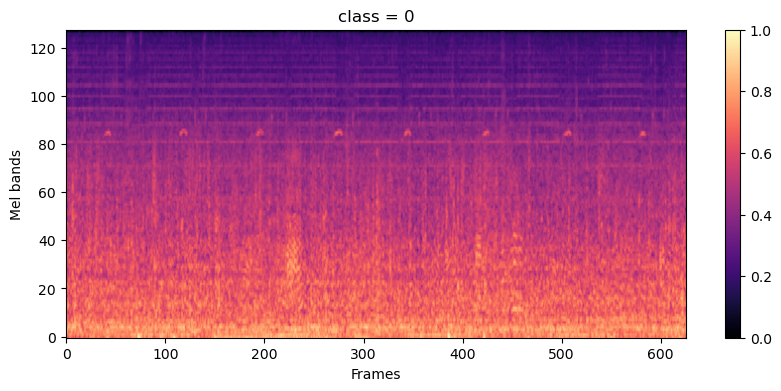

In [ ]:
# import random to preview different spectrograms
import random

random_file = random.choice(df_specs["file"].tolist())
show_mel_spec(random_file)

In [ ]:
# split the data into train / validation / test
train_df, temp_df = train_test_split(df_specs, test_size=0.20, random_state=42, stratify=df_specs["label"])
val_df, test_df  = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df["label"])

In [ ]:
# size of each split
print("Train:", train_df.shape)
print("Val:",   val_df.shape)
print("Test:",  test_df.shape)

Train: (27112, 2)
Val: (3389, 2)
Test: (3390, 2)


In [ ]:
# class distribution in the training and validation sets
print(train_df['label'].value_counts())

print(val_df['label'].value_counts())

label
1    13616
0    13496
Name: count, dtype: int64
label
1    1702
0    1687
Name: count, dtype: int64


In [20]:
# loads the .npy spectrograms from disk and builds the (X, y) arrays for the model

def load_spectrogram_dataset(df, spectrogram_dir):
    X = []
    y = []

    for _, row in df.iterrows():
        file_name = row["file"]
        label = row["label"]

        spec_path = os.path.join(spectrogram_dir, file_name)

        if not os.path.exists(spec_path):
            print("Missing:", spec_path)
            continue

        mel = np.load(spec_path)

        # channel dimension
        mel = mel[..., np.newaxis]

        X.append(mel)
        y.append(label)

    return np.array(X), np.array(y)

In [21]:
X_train, y_train = load_spectrogram_dataset(train_df, spectrogram_dir)
X_val,   y_val   = load_spectrogram_dataset(val_df,   spectrogram_dir)
X_test,  y_test  = load_spectrogram_dataset(test_df,  spectrogram_dir)

In [ ]:
# save the splits
np.save("X_train_2.npy", X_train)
np.save("X_val_2.npy", X_val)
np.save("X_test_2.npy", X_test)
np.save("y_train_2.npy", y_train)
np.save("y_val_2.npy", y_val)
np.save("y_test_2.npt", y_test)

In [ ]:
# load the saved splits so the split is not redone on every run
X_train = np.load("X_train_2.npy")
y_train = np.load("y_train_2.npy")
X_val = np.load("X_val_2.npy")
y_val = np.load("y_val_2.npy")
X_test = np.load("X_test_2.npy")
y_test = np.load("y_test_2.npy")

In [44]:
print(X_train.shape)  
print(X_val.shape)
print(X_test.shape)

(27112, 128, 626, 1)
(3389, 128, 626, 1)
(3390, 128, 626, 1)


In [ ]:
# Hybrid model: CNN + BiLSTM

def bee_model_hybrid(input_shape):


    model = models.Sequential()

    #*********** CNN BLOCK 1 ****************
    model.add(layers.Conv2D(32, (3, 3), activation='relu',
                            padding='same', input_shape=input_shape))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.2))

    #************ CNN BLOCK 2 ****************
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))

    #************* CNN BLOCK 3 *************
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Dropout(0.3))

    #************ RESHAPE *****************
    model.add(layers.Reshape((78, 16 * 128)))

    #************ BiLSTM ******************
    model.add(layers.Bidirectional(layers.LSTM(64, return_sequences=False)))
    model.add(layers.Dropout(0.3))

    #************ CLASSIFICATION ***************
    model.add(layers.Dense(64, activation='relu'))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(1, activation='sigmoid'))

    #************* COMPILATION ****************
    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [ ]:
input_shape = X_train.shape[1:]  # input shape is taken from the data
model = bee_model_hybrid(input_shape)
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 128, 626, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128, 626, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64, 313, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 313, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 313, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 32, 156, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 156, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 156, 128)   │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 16, 78, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 78, 2048)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │     1,081,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,183,745 (4.52 MB)

 Trainable params: 1,183,297 (4.51 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# early stopping and checkpoint settings
early = callbacks.EarlyStopping(patience=10, restore_best_weights=True)
checkpoint = callbacks.ModelCheckpoint("bee_model_best.h5", save_best_only=True)

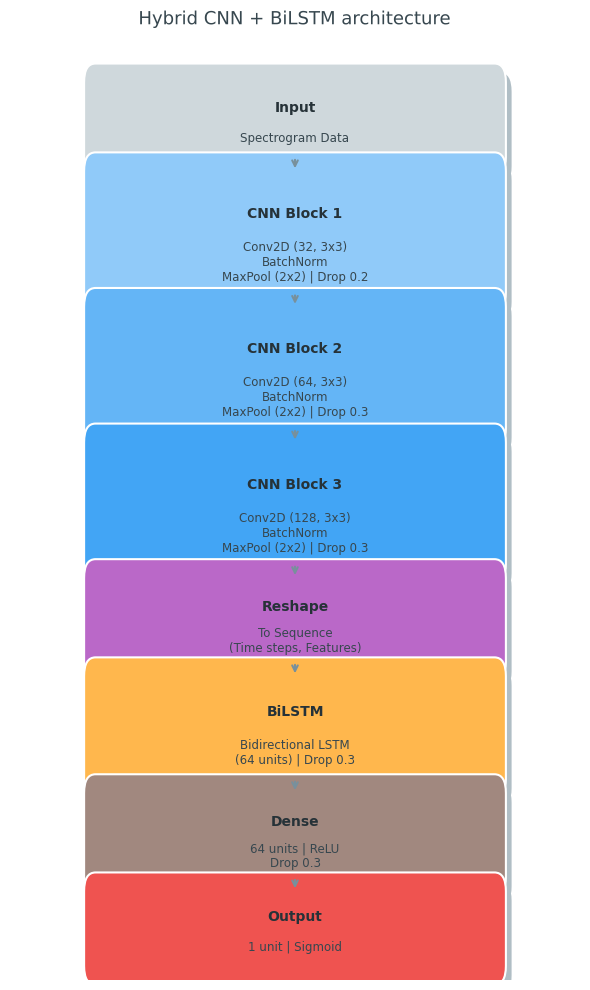

In [335]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_cnn_bilstm_architecture_fixed():
    # Layer configuration with matching heights ("h")
    layers_config = [
        # Input
        {"name": "Input", "desc": "Spectrogram Data", "color": "#cfd8dc", "h": 0.08},
        
        # CNN BLOCK 1
        {"name": "CNN Block 1", "desc": "Conv2D (32, 3x3)\nBatchNorm\nMaxPool (2x2) | Drop 0.2", "color": "#90caf9", "h": 0.13},
        
        # CNN BLOCK 2
        {"name": "CNN Block 2", "desc": "Conv2D (64, 3x3)\nBatchNorm\nMaxPool (2x2) | Drop 0.3", "color": "#64b5f6", "h": 0.13},
        
        # CNN BLOCK 3
        {"name": "CNN Block 3", "desc": "Conv2D (128, 3x3)\nBatchNorm\nMaxPool (2x2) | Drop 0.3", "color": "#42a5f5", "h": 0.13},
        
        # RESHAPE
        {"name": "Reshape", "desc": "To Sequence\n(Time steps, Features)", "color": "#ba68c8", "h": 0.09},
        
        # BiLSTM
        {"name": "BiLSTM", "desc": "Bidirectional LSTM\n(64 units) | Drop 0.3", "color": "#ffb74d", "h": 0.11},
        
        # CLASSIFICATION (Dense)
        {"name": "Dense", "desc": "64 units | ReLU\nDrop 0.3", "color": "#a1887f", "h": 0.09},
        
        # OUTPUT
        {"name": "Output", "desc": "1 unit | Sigmoid", "color": "#ef5350", "h": 0.08}
    ]

    # Figure size (a bit wider and shorter for better proportions)
    fig, ax = plt.subplots(figsize=(6, 10))
    ax.axis('off')
    
    # Drawing parameters
    box_width = 0.7
    start_y = 0.96
    current_y = start_y
    gap = 0.015 # Smaller gap
    
    for i, layer in enumerate(layers_config):
        # 1. Shadow
        shadow_offset = 0.01
        shadow = patches.FancyBboxPatch(
            (0.5 - box_width/2 + shadow_offset, current_y - layer["h"] - shadow_offset), 
            box_width, layer["h"],
            boxstyle="round,pad=0.02", 
            ec="none", fc="#b0bec5", zorder=1
        )
        ax.add_patch(shadow)

        # 2. Main block
        box = patches.FancyBboxPatch(
            (0.5 - box_width/2, current_y - layer["h"]), 
            box_width, layer["h"],
            boxstyle="round,pad=0.02", 
            ec="white", fc=layer["color"], lw=1.5, zorder=2
        )
        ax.add_patch(box)

        # 3. Text (adjusted positions and font size)
        ax.text(0.5, current_y - layer["h"]*0.35, layer["name"], 
                ha='center', va='center', fontsize=10, fontweight='bold', color='#263238', zorder=3)
        ax.text(0.5, current_y - layer["h"]*0.75, layer["desc"], 
                ha='center', va='center', fontsize=8.5, color='#37474f', zorder=3)

        # 4. Arrow
        if i < len(layers_config) - 1:
            arrow_start = current_y - layer["h"]
            # Arrow
            ax.annotate('', xy=(0.5, arrow_start - gap), xytext=(0.5, arrow_start),
                        arrowprops=dict(arrowstyle='->', lw=1.5, color='#78909c'))
            
            current_y -= (layer["h"] + gap)
        else:
            current_y -= layer["h"]

    plt.title("Hybrid CNN + BiLSTM architecture", fontsize=13, pad=15, color='#37474f')
    plt.tight_layout()
    plt.show()

draw_cnn_bilstm_architecture_fixed()

In [ ]:
# train the hybrid model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early, checkpoint]
)

Epoch 1/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6636 - loss: 0.5930

848/848 ━━━━━━━━━━━━━━━━━━━━ 2229s 3s/step - accuracy: 0.7697 - loss: 0.4669 - val_accuracy: 0.8578 - val_loss: 0.3035
Epoch 2/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9493 - loss: 0.1538

848/848 ━━━━━━━━━━━━━━━━━━━━ 2218s 3s/step - accuracy: 0.9585 - loss: 0.1251 - val_accuracy: 0.9672 - val_loss: 0.0873
Epoch 3/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9736 - loss: 0.0757

848/848 ━━━━━━━━━━━━━━━━━━━━ 2224s 3s/step - accuracy: 0.9756 - loss: 0.0707 - val_accuracy: 0.9805 - val_loss: 0.0528
Epoch 4/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9791 - loss: 0.0552

848/848 ━━━━━━━━━━━━━━━━━━━━ 2226s 3s/step - accuracy: 0.9805 - loss: 0.0535 - val_accuracy: 0.9900 - val_loss: 0.0339
Epoch 5/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2227s 3s/step - accuracy: 0.9850 - loss: 0.0443 - val_accuracy: 0.9377 - val_loss: 0.1632
Epoch 6/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2228s 3s/step - accuracy: 0.9868 - loss: 0.0380 - val_accuracy: 0.9811 - val_loss: 0.0513
Epoch 7/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2224s 3s/step - accuracy: 0.9888 - loss: 0.0331 - val_accuracy: 0.9681 - val_loss: 0.1006
Epoch 8/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2225s 3s/step - accuracy: 0.9911 - loss: 0.0256 - val_accuracy: 0.9259 - val_loss: 0.2048
Epoch 9/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9911 - loss: 0.0276

848/848 ━━━━━━━━━━━━━━━━━━━━ 2228s 3s/step - accuracy: 0.9913 - loss: 0.0266 - val_accuracy: 0.9926 - val_loss: 0.0252
Epoch 10/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2228s 3s/step - accuracy: 0.9930 - loss: 0.0217 - val_accuracy: 0.9799 - val_loss: 0.0549
Epoch 11/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2229s 3s/step - accuracy: 0.9933 - loss: 0.0206 - val_accuracy: 0.9852 - val_loss: 0.0389
Epoch 12/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2230s 3s/step - accuracy: 0.9948 - loss: 0.0162 - val_accuracy: 0.9888 - val_loss: 0.0441
Epoch 13/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2225s 3s/step - accuracy: 0.9937 - loss: 0.0182 - val_accuracy: 0.9690 - val_loss: 0.0973
Epoch 14/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9940 - loss: 0.0164

848/848 ━━━━━━━━━━━━━━━━━━━━ 2221s 3s/step - accuracy: 0.9942 - loss: 0.0155 - val_accuracy: 0.9947 - val_loss: 0.0169
Epoch 15/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2194s 3s/step - accuracy: 0.9951 - loss: 0.0146 - val_accuracy: 0.9923 - val_loss: 0.0251
Epoch 16/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2214s 3s/step - accuracy: 0.9948 - loss: 0.0145 - val_accuracy: 0.9917 - val_loss: 0.0253
Epoch 17/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2204s 3s/step - accuracy: 0.9951 - loss: 0.0155 - val_accuracy: 0.9941 - val_loss: 0.0183
Epoch 18/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2208s 3s/step - accuracy: 0.9957 - loss: 0.0110 - val_accuracy: 0.9374 - val_loss: 0.2439
Epoch 19/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9964 - loss: 0.0099

848/848 ━━━━━━━━━━━━━━━━━━━━ 2212s 3s/step - accuracy: 0.9963 - loss: 0.0100 - val_accuracy: 0.9953 - val_loss: 0.0107
Epoch 20/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2207s 3s/step - accuracy: 0.9963 - loss: 0.0112 - val_accuracy: 0.9897 - val_loss: 0.0265
Epoch 21/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2209s 3s/step - accuracy: 0.9967 - loss: 0.0096 - val_accuracy: 0.9852 - val_loss: 0.0472
Epoch 22/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2216s 3s/step - accuracy: 0.9969 - loss: 0.0088 - val_accuracy: 0.9823 - val_loss: 0.0509
Epoch 23/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2206s 3s/step - accuracy: 0.9973 - loss: 0.0081 - val_accuracy: 0.9956 - val_loss: 0.0154
Epoch 24/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2208s 3s/step - accuracy: 0.9976 - loss: 0.0072 - val_accuracy: 0.9962 - val_loss: 0.0120
Epoch 25/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2207s 3s/step - accuracy: 0.9973 - loss: 0.0074 - val_accuracy: 0.9903 - val_loss: 0.0392
Epoch 26/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 2209s 3s/step - accuracy: 0.9979 - loss: 0.0055 - val_

848/848 ━━━━━━━━━━━━━━━━━━━━ 2214s 3s/step - accuracy: 0.9979 - loss: 0.0055 - val_accuracy: 0.9970 - val_loss: 0.0105
Epoch 30/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9984 - loss: 0.0046

848/848 ━━━━━━━━━━━━━━━━━━━━ 2212s 3s/step - accuracy: 0.9984 - loss: 0.0044 - val_accuracy: 0.9965 - val_loss: 0.0103


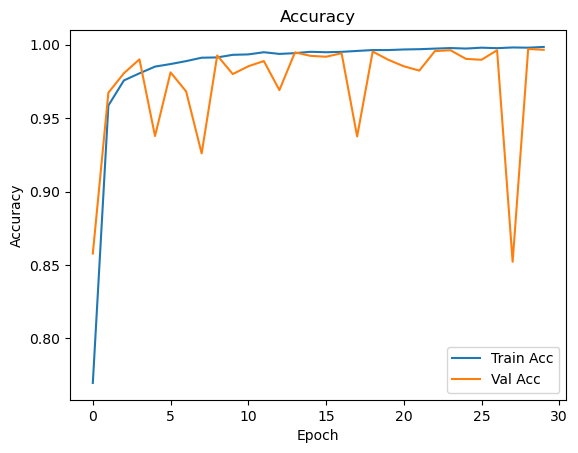

In [187]:
# #Loss
# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history.history['loss'], label='Train Loss')
# plt.plot(history.history['val_loss'], label='Val Loss')
# plt.title('Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()

# #Accuracy
# plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# model predictions
y_pred = (model.predict(X_test) > 0.5).astype(int)

106/106 ━━━━━━━━━━━━━━━━━━━━ 41s 377ms/step


In [ ]:
# classification report
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.999     0.993     0.996      1687
           1      0.994     0.999     0.996      1703

    accuracy                          0.996      3390
   macro avg      0.996     0.996     0.996      3390
weighted avg      0.996     0.996     0.996      3390



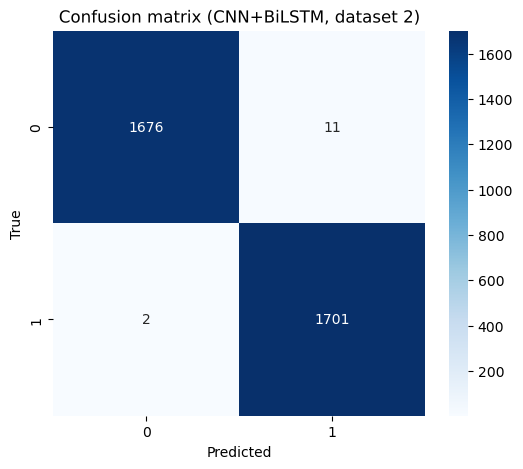

In [ ]:
# confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix (CNN+BiLSTM, dataset 2)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

In [ ]:
# predicted probabilities
y_probs = model.predict(X_test)

106/106 ━━━━━━━━━━━━━━━━━━━━ 40s 376ms/step


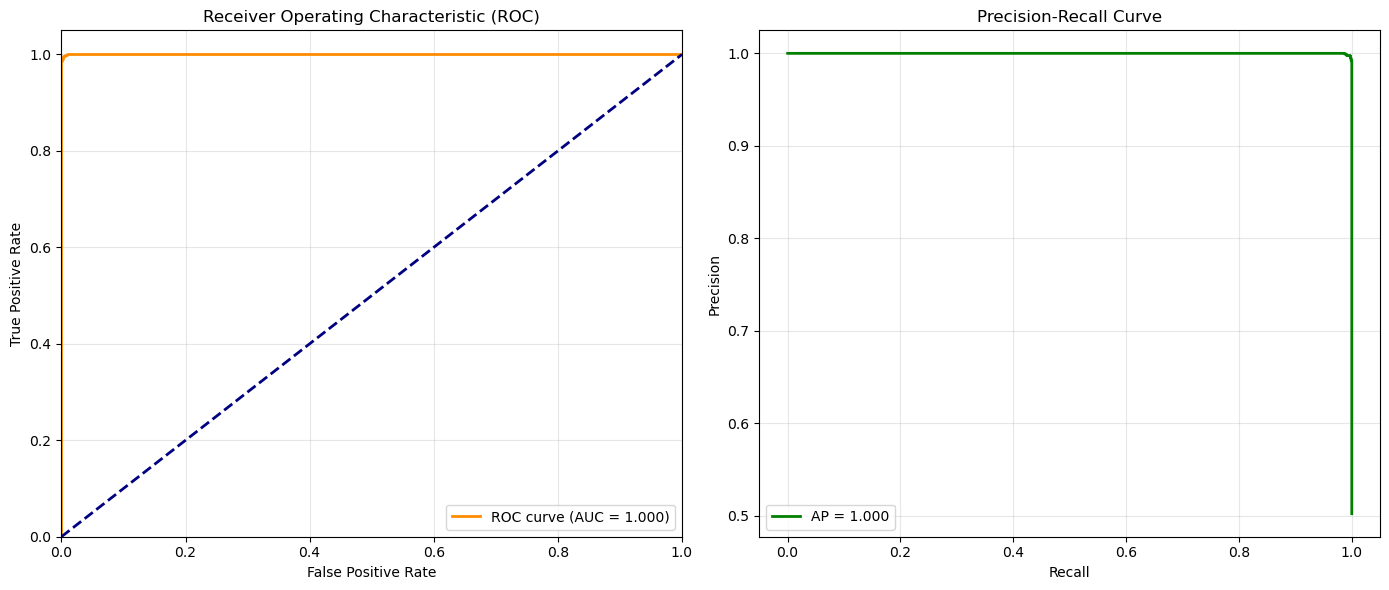

In [ ]:
plt.figure(figsize=(14, 6))

# ROC curve
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Precision-Recall curve
precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)
avg_precision = average_precision_score(y_test, y_probs)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='green', lw=2, label=f'AP = {avg_precision:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [324]:
auc_score = roc_auc_score(y_test, y_probs)

print(f"Exact AUC: {auc_score:.6f}")

Exact AUC: 0.999964


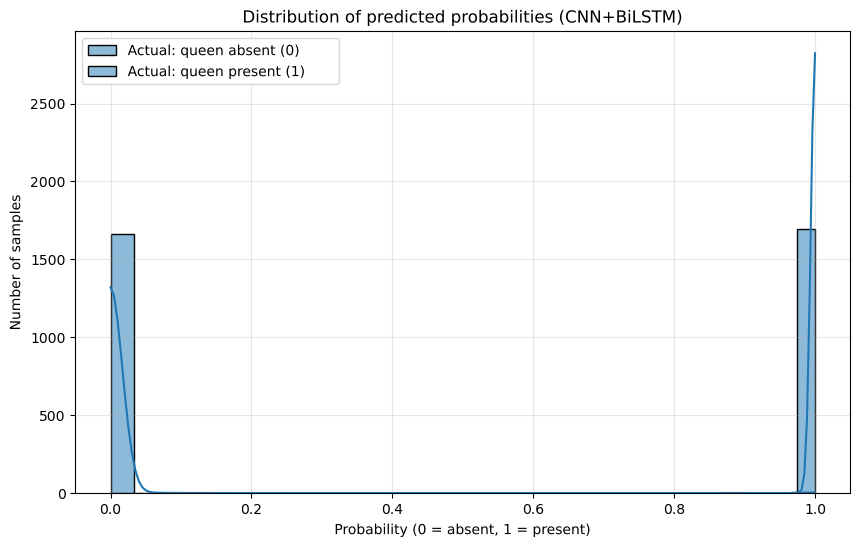

In [325]:
# Histogram of model confidence
plt.figure(figsize=(10, 6))

sns.histplot(y_probs[y_test == 0], color='red', label='Actual: queen absent (0)', kde=True, bins=30, alpha=0.5)
sns.histplot(y_probs[y_test == 1], color='blue', label='Actual: queen present (1)', kde=True, bins=30, alpha=0.5)

plt.title('Distribution of predicted probabilities (CNN+BiLSTM)')
plt.xlabel('Probability (0 = absent, 1 = present)')
plt.ylabel('Number of samples')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# False positive analysis
results_df = test_df.copy().reset_index(drop=True)
results_df["probability"] = y_probs.flatten()
results_df["prediction"] = (y_probs > 0.5).astype(int).flatten()

false_positives = results_df[(results_df["label"] == 0) & (results_df["prediction"] == 1)]

print(f"Number of false positives: {len(false_positives)}")

if not false_positives.empty:
    print("\nExample files wrongly classified as queen present (top 5 by confidence):")
    print(false_positives.sort_values(by="probability", ascending=False).head(5)[["file", "probability"]])
else:
    print("No false positives!")

Number of false positives: 11

Example files wrongly classified as queen present (top 5 by confidence):
                                                   file  probability
1783  Hive1 31_05_2018_NO_QueenBee____00_20_00_slice...     0.999452
1971  Hive1 31_05_2018_NO_QueenBee____19_50_00_slice...     0.999045
1116  Hive1 31_05_2018_NO_QueenBee____19_50_00_slice...     0.998762
2488  Hive1 31_05_2018_NO_QueenBee____00_10_00_slice...     0.998276
1463  Hive1 31_05_2018_NO_QueenBee____12_20_00_slice...     0.967486


In [ ]:
# Computational cost of CNN+BiLSTM
model.save("temp_bee_model_analysis.h5")
model_size_mb = os.path.getsize("temp_bee_model_analysis.h5") / (1024 * 1024)
print(f"Model size on disk: {model_size_mb:.2f} MB")

sample_batch = X_test[:100]

start_time = time.time()
_ = model.predict(sample_batch, verbose=0)
end_time = time.time()

total_time = end_time - start_time
time_per_sample_ms = (total_time / 100) * 1000

print(f"Processing time for 100 samples: {total_time:.4f} s")
print(f"Average time per sample: {time_per_sample_ms:.2f} ms")

if os.path.exists("temp_bee_model_analysis.h5"):
    os.remove("temp_bee_model_analysis.h5")

Model size on disk: 13.64 MB
Processing time for 100 samples: 1.3387 s
Average time per sample: 13.39 ms


___

**MLP**

In [ ]:
# LPC coefficients (17 coefficients, same sampling rate as in the hybrid model)
def extract_lpc_features(file_path, order=16, sr=32000):
    y, sr = librosa.load(file_path, sr=sr)

    # same length as in the spectrograms (10 s)
    target_len = sr * 10
    if len(y) < target_len:
        y = np.pad(y, (0, target_len - len(y)))
    else:
        y = y[:target_len]

    return librosa.lpc(y, order=order)

In [31]:
def build_lpc_from_df(df, audio_dir, order=16):
    X = []
    y = []

    for _, row in df.iterrows():
        wav_name = row["file"].replace(".npy", ".wav")
        wav_path = os.path.join(audio_dir, wav_name)

        lpc = extract_lpc_features(wav_path, order=order)

        X.append(lpc)
        y.append(row["label"])

    return np.array(X), np.array(y)

In [ ]:
# assign the coefficients to the matching recordings (same train/val/test split as for the hybrid model)
X_lpc_train, y_lpc_train = build_lpc_from_df(train_df, audio)
X_lpc_val,   y_lpc_val   = build_lpc_from_df(val_df,   audio)
X_lpc_test,  y_lpc_test  = build_lpc_from_df(test_df,  audio)

In [ ]:
# save the splits
np.save("X_lpc_train_2.npy", X_lpc_train)
np.save("X_lpc_val_2.npy", X_lpc_val)
np.save("X_lpc_test_2.npy", X_lpc_test)
np.save("y_lpc_train_2.npy", y_lpc_train)
np.save("y_lpc_val_2.npy", y_lpc_val)
np.save("y_lpc_test_2.npt", y_lpc_test)

In [ ]:
# load the saved splits
X_lpc_train = np.load("X_lpc_train_2.npy")
y_lpc_train = np.load("y_lpc_train_2.npy")
X_lpc_val = np.load("X_lpc_val_2.npy")
y_lpc_val = np.load("y_lpc_val_2.npy")
X_lpc_test = np.load("X_lpc_test_2.npy")
y_lpc_test = np.load("y_lpc_test_2.npy")

In [ ]:
# MLP architecture and hyperparameters
lpc_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_lpc_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

lpc_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

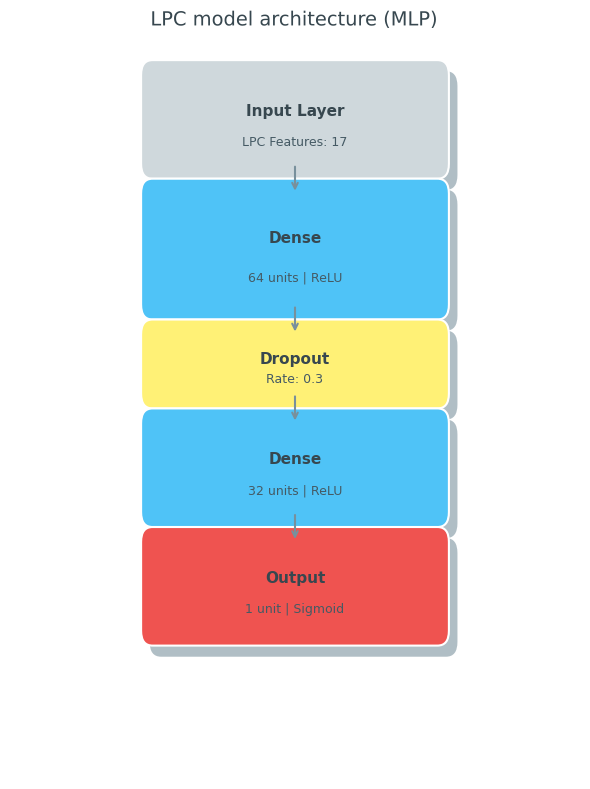

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_lpc_model_final():
    try:
        input_dim = X_lpc_train.shape[1]
    except NameError:
        input_dim = "N"

    layers_config = [
        {"name": "Input Layer", "desc": f"LPC Features: {input_dim}", "color": "#cfd8dc", "h": 0.12},
        {"name": "Dense", "desc": "64 units | ReLU", "color": "#4fc3f7", "h": 0.15},
        {"name": "Dropout", "desc": "Rate: 0.3", "color": "#fff176", "h": 0.08},
        {"name": "Dense", "desc": "32 units | ReLU", "color": "#4fc3f7", "h": 0.12},
        {"name": "Output", "desc": "1 unit | Sigmoid", "color": "#ef5350", "h": 0.12}
    ]

    fig, ax = plt.subplots(figsize=(6, 8))
    ax.axis('off')
    
    box_width = 0.5
    start_y = 0.95
    current_y = start_y
    gap = 0.04

    for i, layer in enumerate(layers_config):
        shadow_offset = 0.015
        shadow = patches.FancyBboxPatch(
            (0.5 - box_width/2 + shadow_offset, current_y - layer["h"] - shadow_offset), 
            box_width, layer["h"],
            boxstyle="round,pad=0.02", 
            ec="none", fc="#b0bec5", zorder=1
        )
        ax.add_patch(shadow)

        box = patches.FancyBboxPatch(
            (0.5 - box_width/2, current_y - layer["h"]), 
            box_width, layer["h"],
            boxstyle="round,pad=0.02", 
            ec="white", fc=layer["color"], lw=1.5, zorder=2
        )
        ax.add_patch(box)

        ax.text(0.5, current_y - layer["h"]*0.4, layer["name"], 
                ha='center', va='center', fontsize=11, fontweight='bold', color='#37474f', zorder=3)
        ax.text(0.5, current_y - layer["h"]*0.75, layer["desc"], 
                ha='center', va='center', fontsize=9, color='#455a64', zorder=3)

        if i < len(layers_config) - 1:
            arrow_start = current_y - layer["h"]
            arrow_len = gap
            ax.annotate('', xy=(0.5, arrow_start - arrow_len), xytext=(0.5, arrow_start),
                        arrowprops=dict(arrowstyle='->', lw=1.5, color='#78909c'))
            
            current_y -= (layer["h"] + gap)
        else:
            current_y -= layer["h"]

    plt.title("LPC model architecture (MLP)", fontsize=14, pad=10, color='#37474f')
    plt.tight_layout()
    plt.show()

draw_lpc_model_final()

In [ ]:
# train the MLP
history_lpc = lpc_model.fit(
    X_lpc_train, y_lpc_train,
    validation_data=(X_lpc_val, y_lpc_val),
    epochs=30,
    batch_size=32,
    verbose=1
)

Epoch 1/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7351 - loss: 13.7890 - val_accuracy: 0.8415 - val_loss: 0.4278
Epoch 2/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8328 - loss: 5.7027 - val_accuracy: 0.8495 - val_loss: 0.3936
Epoch 3/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8489 - loss: 0.3736 - val_accuracy: 0.8672 - val_loss: 0.3392
Epoch 4/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8634 - loss: 0.3475 - val_accuracy: 0.8799 - val_loss: 0.3121
Epoch 5/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8713 - loss: 0.3289 - val_accuracy: 0.8882 - val_loss: 0.2996
Epoch 6/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8758 - loss: 0.3169 - val_accuracy: 0.8893 - val_loss: 0.2923
Epoch 7/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8815 - loss: 0.3069 - val_accuracy: 0.8926 - val_loss: 0.2853
Epoch 8/30
848/848 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8795 - loss: 14.2975 - val_accuracy: 

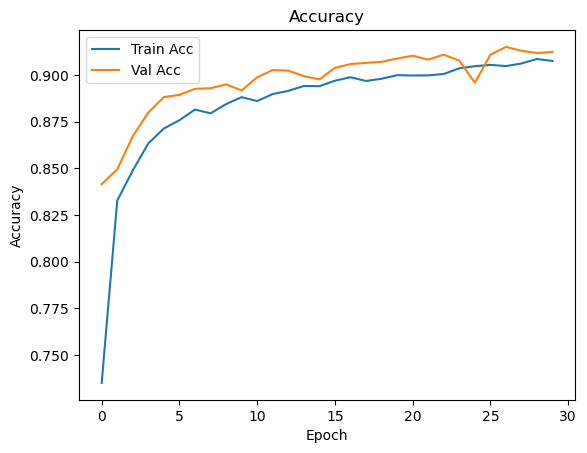

In [186]:
# #Loss
# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.plot(history_lpc.history['loss'], label='Train Loss')
# plt.plot(history_lpc.history['val_loss'], label='Val Loss')
# plt.title('Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()

#Accuracy
# plt.subplot(1, 2, 2)
plt.plot(history_lpc.history['accuracy'], label='Train Acc')
plt.plot(history_lpc.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# MLP classification report
y_lpc_pred = (lpc_model.predict(X_lpc_test) > 0.5).astype(int)

print(classification_report(y_lpc_test, y_lpc_pred, digits=3))

106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
              precision    recall  f1-score   support

           0      0.904     0.932     0.918      1687
           1      0.930     0.903     0.916      1703

    accuracy                          0.917      3390
   macro avg      0.917     0.917     0.917      3390
weighted avg      0.917     0.917     0.917      3390



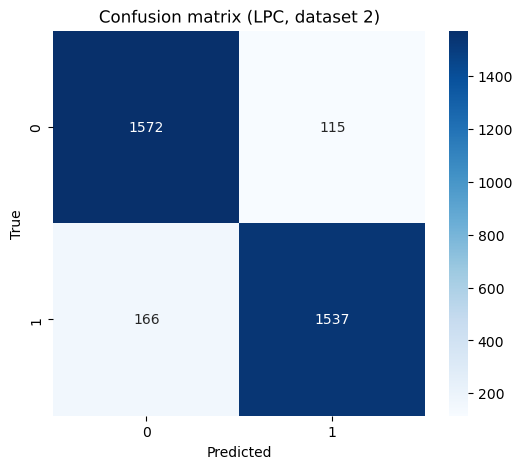

In [ ]:
# confusion matrix
cm_lpc = confusion_matrix(y_lpc_test, y_lpc_pred)

# 2. Plot the chart
plt.figure(figsize=(6, 5))
sns.heatmap(cm_lpc, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion matrix (LPC, dataset 2)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

In [ ]:
# probabilities predicted by the MLP
y_lpc_probs = lpc_model.predict(X_lpc_test)

106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 816us/step


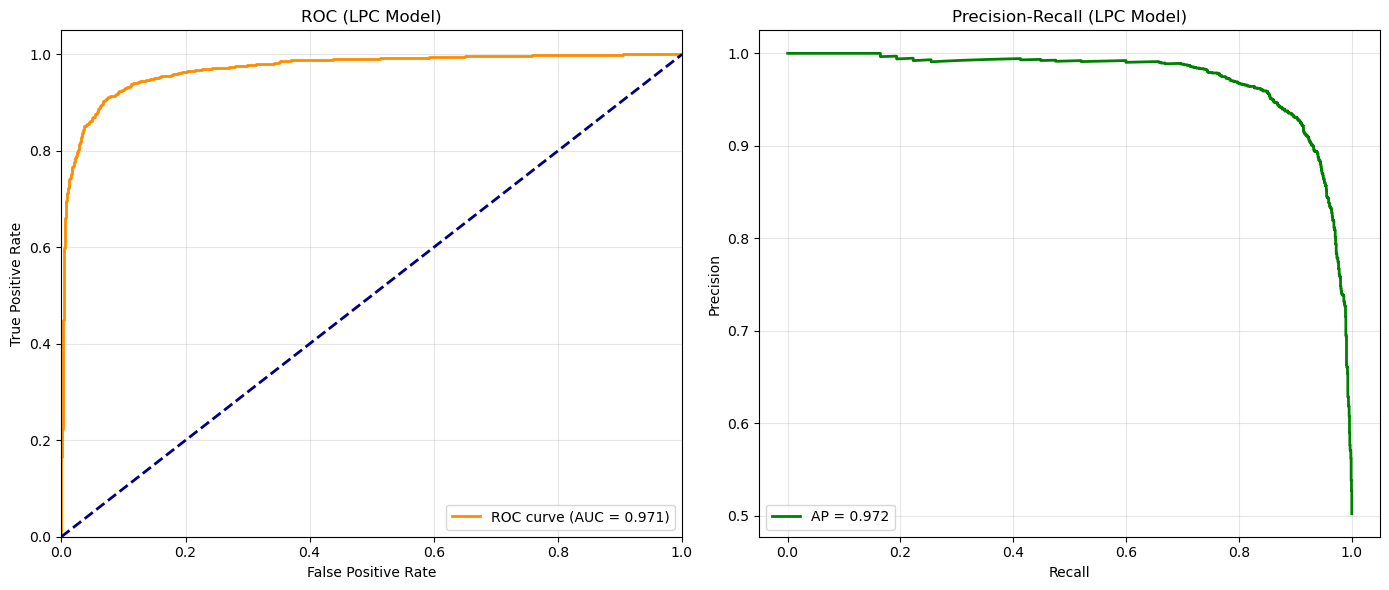

In [319]:
plt.figure(figsize=(14, 6))

# ROC curve (LPC)
fpr, tpr, thresholds_roc = roc_curve(y_lpc_test, y_lpc_probs)
roc_auc = auc(fpr, tpr)

plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC (LPC Model)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Precision-Recall curve (LPC)
precision, recall, thresholds_pr = precision_recall_curve(y_lpc_test, y_lpc_probs)
avg_precision = average_precision_score(y_lpc_test, y_lpc_probs)

plt.subplot(1, 2, 2)
plt.plot(recall, precision, color='green', lw=2, label=f'AP = {avg_precision:.3f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall (LPC Model)')
plt.legend(loc="lower left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

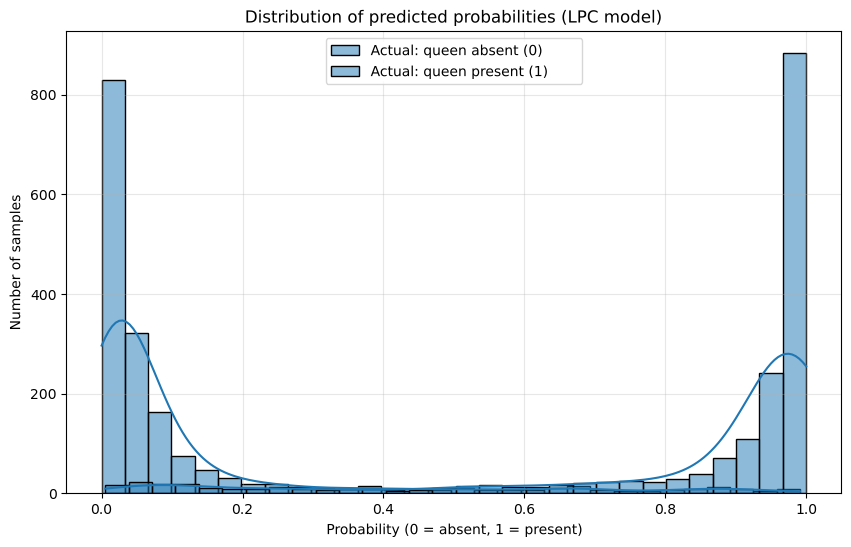

In [320]:
# Histogram of model confidence (LPC)
plt.figure(figsize=(10, 6))

sns.histplot(y_lpc_probs[y_lpc_test == 0], color='red', label='Actual: queen absent (0)', kde=True, bins=30, alpha=0.5)
sns.histplot(y_lpc_probs[y_lpc_test == 1], color='blue', label='Actual: queen present (1)', kde=True, bins=30, alpha=0.5)

plt.title('Distribution of predicted probabilities (LPC model)')
plt.xlabel('Probability (0 = absent, 1 = present)')
plt.ylabel('Number of samples')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [321]:
# False positive analysis
results_lpc_df = test_df.copy().reset_index(drop=True)
results_lpc_df["probability"] = y_lpc_probs.flatten()
results_lpc_df["prediction"] = (y_lpc_probs > 0.5).astype(int).flatten()

false_positives_lpc = results_lpc_df[(results_lpc_df["label"] == 0) & (results_lpc_df["prediction"] == 1)]

print(f"Number of false positives (LPC): {len(false_positives_lpc)}")

if not false_positives_lpc.empty:
    print("\nExample files wrongly classified as queen present by LPC (top 5 by confidence):")
    print(false_positives_lpc.sort_values(by="probability", ascending=False).head(5)[["file", "probability"]])
else:
    print("No false positives in the LPC model!")

Number of false positives (LPC): 115

Example files wrongly classified as queen present by LPC (top 5 by confidence):
                                                   file  probability
918   Hive3_14_07_2017_NO_QueenBee____15_30_00_slice...     0.991093
569   Hive1 31_05_2018_NO_QueenBee____21_00_00_slice...     0.989960
2061  Hive3_14_07_2017_NO_QueenBee____03_50_00_slice...     0.988706
1722  Hive3_14_07_2017_NO_QueenBee____03_50_00_slice...     0.987385
1265  Hive3_14_07_2017_NO_QueenBee____03_10_00_slice...     0.977974


In [ ]:
# Computational cost of the LPC model
lpc_model.save("temp_lpc_model.h5")
model_size_mb = os.path.getsize("temp_lpc_model.h5") / (1024 * 1024)
print(f"LPC model size on disk: {model_size_mb:.4f} MB")

sample_batch = X_lpc_test[:100]

start_time = time.time()
_ = lpc_model.predict(sample_batch, verbose=0)
end_time = time.time()

total_time = end_time - start_time
time_per_sample_ms = (total_time / 100) * 1000

print(f"Processing time for 100 samples: {total_time:.4f} s")
print(f"Average time per sample: {time_per_sample_ms:.4f} ms")

if os.path.exists("temp_lpc_model.h5"):
    os.remove("temp_lpc_model.h5")

LPC model size on disk: 0.0680 MB
Processing time for 100 samples: 0.0912 s
Average time per sample: 0.9121 ms


**Leakage safeguards**

In [42]:
# check that no file appears in more than one set
train_files = set(train_df["file"])
test_files  = set(test_df["file"])

len(train_files.intersection(test_files))

0